# MPD reweighting schematic (paper Fig. `fig:macrostate_reweighting_schematic`)

Illustrates Eqs. `eq:macrostate_mixture_reweighting` and `eq:main_mpd_loading` with a two-component distribution that
is known exactly: a one-dimensional lattice gas of $M$ sites in which a molecule of component 1 occupies two adjacent
sites and a molecule of component 2 one site. A macrostate $\mathbf n=(n_1,n_2)$ leaves $h=M-2n_1-n_2\geq0$ sites
empty and can be arranged in

$$g(\mathbf n)=\frac{(n_1+n_2+h)!}{n_1!\,n_2!\,h!}$$

ways along the line, so the grand-canonical distribution at the reference state, with the common reference fugacity
$f^{\mathrm{ref}}$ of every component, is

$$\Pi_{\mathrm{ref}}(\mathbf n)\propto g(\mathbf n)\,(K_1f^{\mathrm{ref}})^{n_1}(K_2f^{\mathrm{ref}})^{n_2},$$

with $K_j$ the adsorption constant of one placement. Component 1 binds more strongly ($K_1=3K_2$) and wins at low
fugacity; near saturation the smaller component 2 fills the sites more efficiently and displaces it (size entropy). The
distribution is reweighted at the reference temperature, so Eq. `eq:macrostate_mixture_reweighting` reduces to

$$\ln\widetilde\Pi(\mathbf n;f,\mathbf y)=\ln\Pi_{\mathrm{ref}}(\mathbf n)+\sum_j n_j\ln y_j+N\ln\frac{f}{f^{\mathrm{ref}}},$$

and $q_j^*=\langle N_j\rangle/(N_{\mathrm A}m_{\mathrm{fw}})$, with $m_{\mathrm{fw}}$ chosen such that the full lattice
of component 2 holds 4 mol/kg.

Run from `validation/3.2.2_mpd`. The two panels are written to `ruptura-2.0-paper/figures/mpd_reweighting/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.special import gammaln

ROOT = Path.cwd().resolve()
REPOSITORY = ROOT.parent.parent
FIGURE_DIR = REPOSITORY / "ruptura-2.0-paper" / "figures" / "mpd_reweighting"
if not FIGURE_DIR.parent.is_dir():
    raise FileNotFoundError("Run this notebook from validation/3.2.2_mpd, next to ../../ruptura-2.0-paper.")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

AVOGADRO = 6.02214076e23  # mol^-1
SITES = 80  # lattice sites M
ADSORPTION_CONSTANTS = (3.0e-4, 1.0e-4)  # K_1, K_2 per placement [Pa^-1]
REFERENCE_FUGACITY = 1.0e5  # f_ref of every component [Pa]
MOLE_FRACTIONS = (0.5, 0.5)  # equimolar gas, y_1 and y_2 [-]
FRAMEWORK_MASS = SITES / (4.0 * AVOGADRO)  # m_fw [kg]: the full lattice of component 2 holds 4 mol/kg
STATES = (1.0e3, 1.0e4, 1.0e5, 1.0e6)  # total fugacities f of the four reweighted distributions [Pa]
SWEEP = np.logspace(2.0, 7.0, 201)  # total fugacities of the isotherm [Pa]

plt.rcParams.update({
    "figure.figsize": (8, 6),
    # The panels are printed at 0.49 of the A4 text width (3.07 in), i.e. at 38% of their 8 in width.
    # These sizes print as 8.1 pt (ticks, legends) and 8.8 pt (axis labels).
    "font.size": 23,
    "axes.labelsize": 23,
    "axes.titlesize": 25,
    "xtick.labelsize": 21,
    "ytick.labelsize": 21,
    "legend.fontsize": 21,
    "legend.title_fontsize": 21,
    "axes.labelpad": 6.0,
    "lines.linewidth": 3.0,
    "lines.markersize": 10,
    "lines.markeredgewidth": 1.8,
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "legend.handlelength": 1.6,
    "legend.labelspacing": 0.3,
    "legend.borderaxespad": 0.3,
    "legend.columnspacing": 1.0,
    "axes.grid": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
})

## Data handling

In [2]:
# Macrostate grid: n_1 along axis 0, n_2 along axis 1; states with h < 0 do not fit on the lattice.
N1 = np.arange(SITES // 2 + 1)[:, None]
N2 = np.arange(SITES + 1)[None, :]
EMPTY_SITES = SITES - 2 * N1 - N2
VALID = EMPTY_SITES >= 0
holes = np.where(VALID, EMPTY_SITES, 0)
log_reference = np.where(
    VALID,
    gammaln(N1 + N2 + holes + 1) - gammaln(N1 + 1) - gammaln(N2 + 1) - gammaln(holes + 1)
    + N1 * np.log(ADSORPTION_CONSTANTS[0] * REFERENCE_FUGACITY)
    + N2 * np.log(ADSORPTION_CONSTANTS[1] * REFERENCE_FUGACITY),
    -np.inf,
)
log_reference -= log_reference.max() + np.log(np.exp(log_reference - log_reference.max()).sum())

# Pi(n; f, y) at the reference temperature, for the four STATES followed by the SWEEP
fugacities = np.concatenate([STATES, SWEEP])
log_weight = ((log_reference + N1 * np.log(MOLE_FRACTIONS[0]) + N2 * np.log(MOLE_FRACTIONS[1]))[None]
              + (N1 + N2)[None] * np.log(fugacities / REFERENCE_FUGACITY)[:, None, None])
probability = np.exp(log_weight - log_weight.max(axis=(1, 2), keepdims=True))
probability /= probability.sum(axis=(1, 2), keepdims=True)
means = np.stack([(probability * N1).sum(axis=(1, 2)), (probability * N2).sum(axis=(1, 2))], axis=1)

DISTRIBUTIONS = probability[:len(STATES)]  # Pi(n; f, y) [-] of the four STATES
STATE_MEANS = means[:len(STATES)]  # <N_1>, <N_2> [-] of the four STATES
SWEEP_MEANS = means[len(STATES):]  # <N_1>, <N_2> [-] along the SWEEP

In [3]:
print(f"m_fw = {FRAMEWORK_MASS:.4e} kg, {AVOGADRO * FRAMEWORK_MASS:.1f} molecules per mol/kg")
print(f"{'f / Pa':>8s} {'<N_1>':>7s} {'<N_2>':>7s} {'x_1':>6s} {'occupied':>9s} {'q_1':>6s} {'q_2':>6s}")
for fugacity, (first, second) in zip(STATES, STATE_MEANS):
    q_1, q_2 = np.array([first, second]) / (AVOGADRO * FRAMEWORK_MASS)
    print(f"{fugacity:8.0e} {first:7.2f} {second:7.2f} {first / (first + second):6.2f} "
          f"{(2.0 * first + second) / SITES:9.2f} {q_1:6.3f} {q_2:6.3f}")

m_fw = 3.3211e-23 kg, 20.0 molecules per mol/kg
  f / Pa   <N_1>   <N_2>    x_1  occupied    q_1    q_2
   1e+03    7.73    3.07   0.72      0.23  0.387  0.154
   1e+04   18.99   14.01   0.58      0.65  0.949  0.700
   1e+05   15.39   41.02   0.27      0.90  0.769  2.051
   1e+06    3.90   70.79   0.05      0.98  0.195  3.539


## (a) Reweighted distributions

Contours at 0.1, 0.4, and 0.7 of the largest probability of each distribution, mean particle numbers (filled circles),
and the path of $\langle\mathbf n\rangle$ from $10^2$ to $10^7$ Pa. Grey: macrostates beyond the full lattice,
$2n_1+n_2>M$.

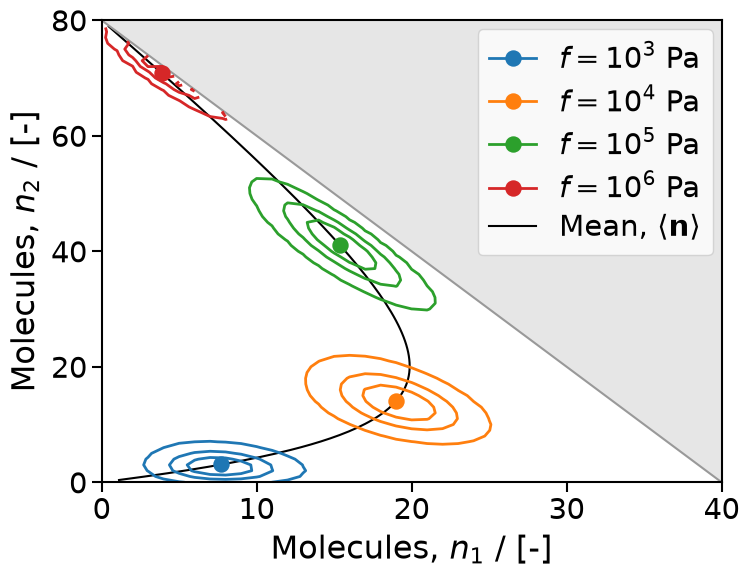

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.fill([0.0, SITES / 2, SITES / 2], [SITES, 0.0, SITES], color="0.9", linewidth=0)
ax.plot([0.0, SITES / 2], [SITES, 0.0], color="0.6", linewidth=1.5)

ax.plot(SWEEP_MEANS[:, 0], SWEEP_MEANS[:, 1], color="k", linewidth=1.5, zorder=1)

handles = []
for index, (fugacity, probability, mean) in enumerate(zip(STATES, DISTRIBUTIONS, STATE_MEANS)):
    color = f"C{index}"
    ax.contour(N1.ravel(), N2.ravel(), np.ma.masked_where(~VALID, probability / probability.max()).T,
               levels=[0.1, 0.4, 0.7], colors=color, linewidths=2.0)
    ax.plot(*mean, color=color, marker="o", linestyle="none")
    handles.append(plt.Line2D([], [], color=color, linewidth=2.0, marker="o",
                              label=rf"$f=10^{{{np.log10(fugacity):.0f}}}$ Pa"))
handles.append(plt.Line2D([], [], color="k", linewidth=1.5, label=r"Mean, $\langle\mathbf{n}\rangle$"))
ax.legend(handles=handles, loc="upper right")

ax.set_xlim(0.0, SITES / 2)
ax.set_ylim(0.0, SITES)
ax.set_xlabel(r"Molecules, $n_1$ / [-]")
ax.set_ylabel(r"Molecules, $n_2$ / [-]")
fig.savefig(FIGURE_DIR / "distributions.pdf", dpi=300, bbox_inches="tight")
plt.show()

## (b) Mixture isotherm

Equimolar loadings from the mean particle numbers of the reweighted distributions; the circles mark the four
distributions of (a) in their colors.

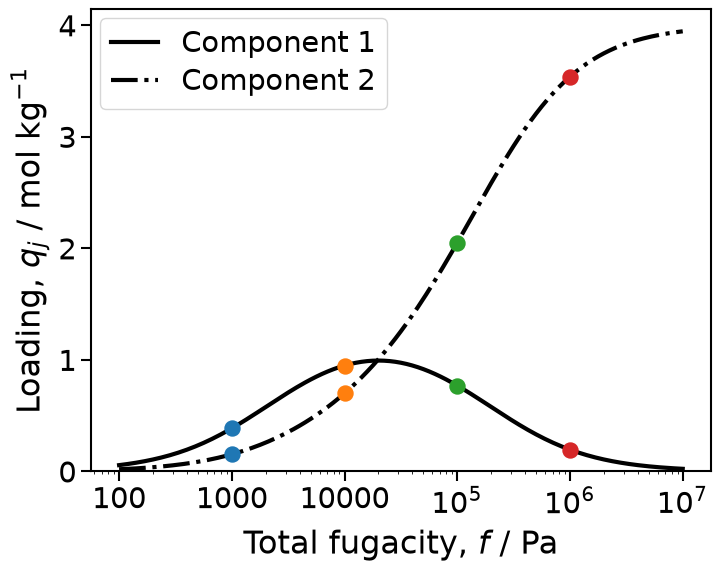

In [5]:
loading = SWEEP_MEANS / (AVOGADRO * FRAMEWORK_MASS)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(SWEEP, loading[:, 0], color="k", linestyle="-", label="Component 1")
ax.plot(SWEEP, loading[:, 1], color="k", linestyle="-.", label="Component 2")
for index, (fugacity, mean) in enumerate(zip(STATES, STATE_MEANS)):
    ax.plot([fugacity, fugacity], mean / (AVOGADRO * FRAMEWORK_MASS), color=f"C{index}", marker="o", linestyle="none",
            zorder=3)
ax.legend(loc="upper left")

ax.set_xscale("log")
ax.set_xticks([1e2, 1e3, 1e4, 1e5, 1e6, 1e7], ["100", "1000", "10000", r"$10^{5}$", r"$10^{6}$", r"$10^{7}$"])
ax.set_ylim(bottom=0.0)
ax.set_xlabel("Total fugacity, $f$ / Pa")
ax.set_ylabel(r"Loading, $q_j$ / mol kg$^{-1}$")
fig.savefig(FIGURE_DIR / "isotherm.pdf", dpi=300, bbox_inches="tight")
plt.show()